In [3]:
import tensorflow as tf
from tensorflow.keras import layers, Sequential

latent_dim = 100

# Generator
generator = Sequential([
    layers.Input(shape=(latent_dim,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(256, activation="relu"),
    layers.Dense(784, activation="tanh"),
    layers.Reshape((28, 28, 1))
])

# Discriminator
discriminator = Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

discriminator.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [4]:
# Load MNIST
(x_train, _), (_, _) = tf.keras.datasets.mnist.load_data()

# Normalize to [-1, 1] to match tanh output
x_train = (x_train.astype("float32") - 127.5) / 127.5
x_train = x_train.reshape(-1, 28, 28, 1)

batch_size = 128
dataset = tf.data.Dataset.from_tensor_slices(x_train)
dataset = dataset.shuffle(60000).batch(batch_size, drop_remainder=True)

# Combined GAN
discriminator.trainable = False

gan = Sequential([generator, discriminator])

gan.compile(
    optimizer=tf.keras.optimizers.Adam(0.0002),
    loss="binary_crossentropy"
)

discriminator.trainable = True

In [5]:
epochs = 10

for epoch in range(epochs):
    for real_images in dataset:

        batch_size = real_images.shape[0]

        # Generate fake images
        noise = tf.random.normal((batch_size, latent_dim))
        fake_images = generator(noise, training=True)

        # Train discriminator on real images
        real_labels = tf.ones((batch_size, 1))
        d_loss_real = discriminator.train_on_batch(
            real_images, real_labels
        )

        # Train discriminator on generated images
        fake_labels = tf.zeros((batch_size, 1))
        d_loss_fake = discriminator.train_on_batch(
            fake_images, fake_labels
        )

        # Train generator to fool discriminator
        noise = tf.random.normal((batch_size, latent_dim))
        misleading_labels = tf.ones((batch_size, 1))

        g_loss = gan.train_on_batch(
            noise, misleading_labels
        )

    print(f"Epoch {epoch + 1}/{epochs} completed")

Epoch 1/10 completed
Epoch 2/10 completed
Epoch 3/10 completed
Epoch 4/10 completed
Epoch 5/10 completed
Epoch 6/10 completed
Epoch 7/10 completed
Epoch 8/10 completed
Epoch 9/10 completed
Epoch 10/10 completed


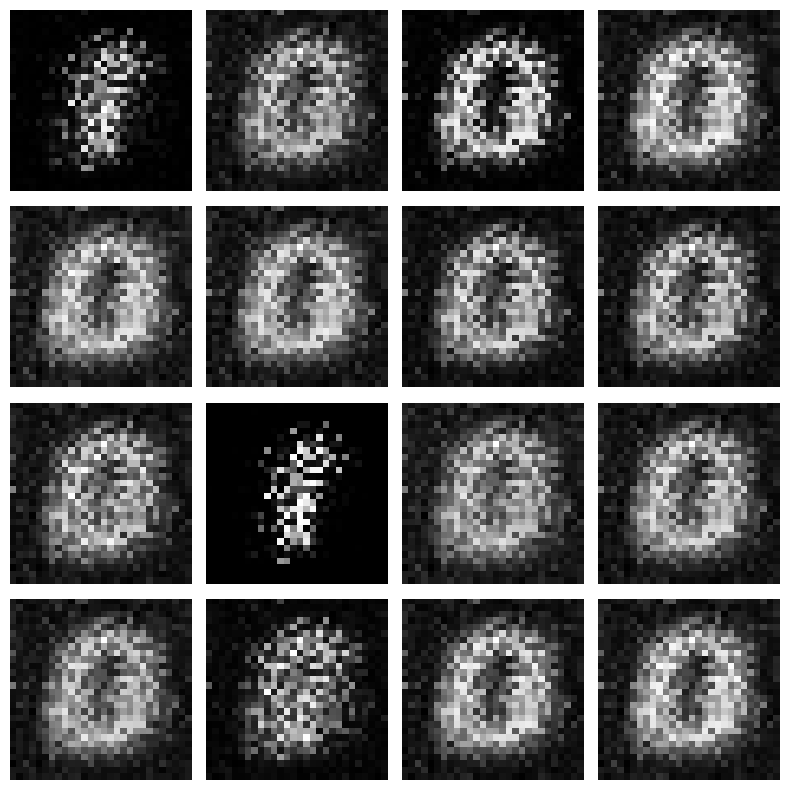

In [6]:
import matplotlib.pyplot as plt

noise = tf.random.normal((16, latent_dim))
generated_images = generator(noise, training=False)

plt.figure(figsize=(8, 8))

for i in range(16):
    image = generated_images[i, :, :, 0]
    image = (image + 1) / 2  # Convert back to [0, 1]

    plt.subplot(4, 4, i + 1)
    plt.imshow(image, cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()